# PS5: Facial Emotion Recognition using a CNN (FER-2013)
7 emotions: angry, disgust, fear, happy, neutral, sad, surprise (48x48 grayscale).

In [1]:

import subprocess
import tensorflow as tf

MIN_FREE_VRAM_MB = 2048

gpus = tf.config.list_physical_devices('GPU')

if not gpus:
    print('=' * 66)
    print('GPU NOT FOUND - Running CNN on CPU instead.')
    print('CPU training may take longer.')
    print('=' * 66)
    device_name = 'CPU'
    free_mb = None
    policy = 'float32'

else:
    for gpu in gpus:
        try:
            tf.config.experimental.set_memory_growth(gpu, True)
        except RuntimeError:
            pass

    free_mb = None

    try:
        out = subprocess.check_output(
            ['nvidia-smi', '--query-gpu=memory.free', '--format=csv,noheader,nounits'],
            text=True, stderr=subprocess.DEVNULL)
        free_mb = max(int(v) for v in out.split())
    except Exception:
        print('Note: nvidia-smi not available; skipping free-VRAM measurement.')

    if free_mb is not None and free_mb < MIN_FREE_VRAM_MB:
        print('Not enough free VRAM. Running on CPU instead.')
        device_name = 'CPU'
        policy = 'float32'
    else:
        device_name = gpus[0].name
        policy = 'mixed_float16'

tf.keras.mixed_precision.set_global_policy(policy)

print('TensorFlow:', tf.__version__)
print('Device:', device_name)
print('Free VRAM (MB):', free_mb if free_mb is not None else 'N/A')
print('Policy:', tf.keras.mixed_precision.global_policy().name)


GPU NOT FOUND - Running CNN on CPU instead.
CPU training may take longer.
TensorFlow: 2.21.0
Device: CPU
Free VRAM (MB): N/A
Policy: float32


In [2]:

import pathlib
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import kagglehub
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
from tensorflow import keras
from tensorflow.keras import layers

DATA_DIR = kagglehub.dataset_download('msambare/fer2013')

IMG = (48, 48)
BATCH = 32
EPOCHS = 10
SEED = 42

keras.utils.set_random_seed(SEED)

print("Dataset path:", DATA_DIR)


Dataset path: C:\Users\DELL\.cache\kagglehub\datasets\msambare\fer2013\versions\1


In [3]:
%pip install ipywidgets

Note: you may need to restart the kernel to use updated packages.


In [4]:
%pip install -U jupyter ipywidgets widgetsnbextension

Note: you may need to restart the kernel to use updated packages.


In [5]:

train_dir = pathlib.Path(DATA_DIR) / 'train'
test_dir = pathlib.Path(DATA_DIR) / 'test'

if not train_dir.is_dir() or not test_dir.is_dir():
    raise SystemExit(
        f'Stopped: {DATA_DIR} must contain train/ and test/ folders.'
    )

print('Dataset directory:', DATA_DIR)
print('Training folder found:', train_dir.is_dir())
print('Testing folder found:', test_dir.is_dir())


Dataset directory: C:\Users\DELL\.cache\kagglehub\datasets\msambare\fer2013\versions\1
Training folder found: True
Testing folder found: True


In [6]:
train_ds = keras.utils.image_dataset_from_directory(
    train_dir, color_mode='grayscale', image_size=IMG, batch_size=BATCH,
    label_mode='int', validation_split=0.1, subset='training', seed=SEED)
val_ds = keras.utils.image_dataset_from_directory(
    train_dir, color_mode='grayscale', image_size=IMG, batch_size=BATCH,
    label_mode='int', validation_split=0.1, subset='validation', seed=SEED)
test_ds = keras.utils.image_dataset_from_directory(
    test_dir, color_mode='grayscale', image_size=IMG, batch_size=BATCH,
    label_mode='int', shuffle=False)
class_names = train_ds.class_names
num_classes = len(class_names)
print('Classes:', class_names)

train_ds = train_ds.cache()
val_ds = val_ds.cache()
test_ds = test_ds.cache()
y_train_all = np.concatenate([y.numpy() for _, y in train_ds])
weights = compute_class_weight('balanced', classes=np.arange(num_classes), y=y_train_all)
class_weight = dict(enumerate(weights))
print('Class weights:', {class_names[k]: round(float(v), 2) for k, v in class_weight.items()})

Found 28709 files belonging to 7 classes.
Using 25839 files for training.
Found 28709 files belonging to 7 classes.
Using 2870 files for validation.
Found 7178 files belonging to 7 classes.
Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Class weights: {'angry': 1.02, 'disgust': 9.3, 'fear': 1.01, 'happy': 0.57, 'neutral': 0.82, 'sad': 0.85, 'surprise': 1.31}


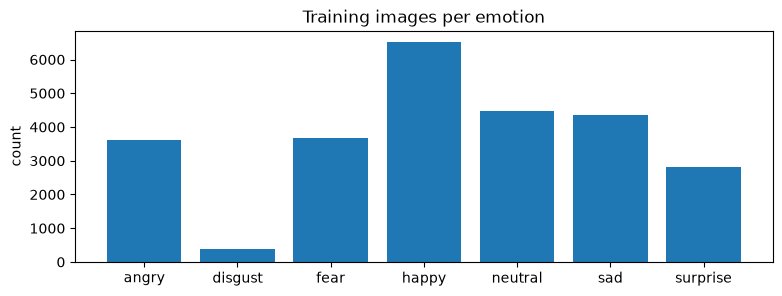

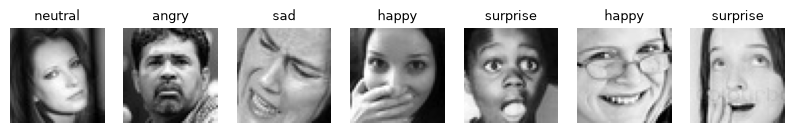

In [7]:
counts = np.bincount(y_train_all, minlength=num_classes)
plt.figure(figsize=(9, 3))
plt.bar(class_names, counts)
plt.title('Training images per emotion')
plt.ylabel('count')
plt.show()

plt.figure(figsize=(10, 3))
for images, labels in train_ds.take(1):
    for i in range(7):
        plt.subplot(1, 7, i + 1)
        plt.imshow(images[i].numpy().squeeze(), cmap='gray')
        plt.title(class_names[labels[i]], fontsize=9)
        plt.axis('off')
plt.show()

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.shuffle(2048, seed=SEED).prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

## Model

In [8]:
model = keras.Sequential([
    layers.Input(IMG + (1,)),
    layers.Rescaling(1.0 / 255),
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.Conv2D(32, 3, padding='same', use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.Conv2D(32, 3, padding='same', use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D(),
    layers.Dropout(0.25),
    layers.Conv2D(64, 3, padding='same', use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.Conv2D(64, 3, padding='same', use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D(),
    layers.Dropout(0.25),
    layers.Conv2D(128, 3, padding='same', use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.Conv2D(128, 3, padding='same', use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D(),
    layers.Dropout(0.25),
    layers.Flatten(),
    layers.Dense(256, use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.Dropout(0.5),
    layers.Dense(num_classes, activation='softmax', dtype='float32'),
])
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)                │ (None, 48, 48, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ random_flip (RandomFlip)             │ (None, 48, 48, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ random_rotation (RandomRotation)     │ (None, 48, 48, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ random_zoom (RandomZoom)             │ (None, 48, 48, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 48, 48, 32)          │             288 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 48, 48, 32)          │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation (Activation)              │ (None, 48, 48, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 48, 48, 32)          │           9,216 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 48, 48, 32)          │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_1 (Activation)            │ (None, 48, 48, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 24, 24, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 24, 24, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 24, 24, 64)          │          18,432 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 24, 24, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_2 (Activation)            │ (None, 24, 24, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 24, 24, 64)          │          36,864 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 24, 24, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_3 (Activation)            │ (None, 24, 24, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 12, 12, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼──────────────

 Total params: 1,470,247 (5.61 MB)

 Trainable params: 1,468,839 (5.60 MB)

 Non-trainable params: 1,408 (5.50 KB)

## Training

In [9]:
callbacks = [
    keras.callbacks.ModelCheckpoint('best_emotion_cnn.keras', monitor='val_accuracy', save_best_only=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6, verbose=1),
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=12, restore_best_weights=True),
]
history = model.fit(
    train_ds, validation_data=val_ds, epochs=EPOCHS,
    class_weight=class_weight, callbacks=callbacks, verbose=2)

Epoch 1/10


C:\Users\DELL\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


808/808 - 174s - 216ms/step - accuracy: 0.1904 - loss: 2.1037 - val_accuracy: 0.2453 - val_loss: 1.8326 - learning_rate: 0.0010
Epoch 2/10
808/808 - 117s - 145ms/step - accuracy: 0.2433 - loss: 1.8598 - val_accuracy: 0.3401 - val_loss: 1.6839 - learning_rate: 0.0010
Epoch 3/10
808/808 - 121s - 150ms/step - accuracy: 0.3051 - loss: 1.7436 - val_accuracy: 0.3380 - val_loss: 1.6700 - learning_rate: 0.0010
Epoch 4/10
808/808 - 124s - 153ms/step - accuracy: 0.3572 - loss: 1.6398 - val_accuracy: 0.4164 - val_loss: 1.5337 - learning_rate: 0.0010
Epoch 5/10
808/808 - 126s - 156ms/step - accuracy: 0.3938 - loss: 1.5639 - val_accuracy: 0.3024 - val_loss: 1.7200 - learning_rate: 0.0010
Epoch 6/10
808/808 - 127s - 157ms/step - accuracy: 0.4130 - loss: 1.5145 - val_accuracy: 0.4118 - val_loss: 1.5195 - learning_rate: 0.0010
Epoch 7/10
808/808 - 126s - 156ms/step - accuracy: 0.4286 - loss: 1.4758 - val_accuracy: 0.4544 - val_loss: 1.4112 - learning_rate: 0.0010
Epoch 8/10
808/808 - 126s - 156ms/step

## Evaluation

Test accuracy: 0.5203   Test loss: 1.2285


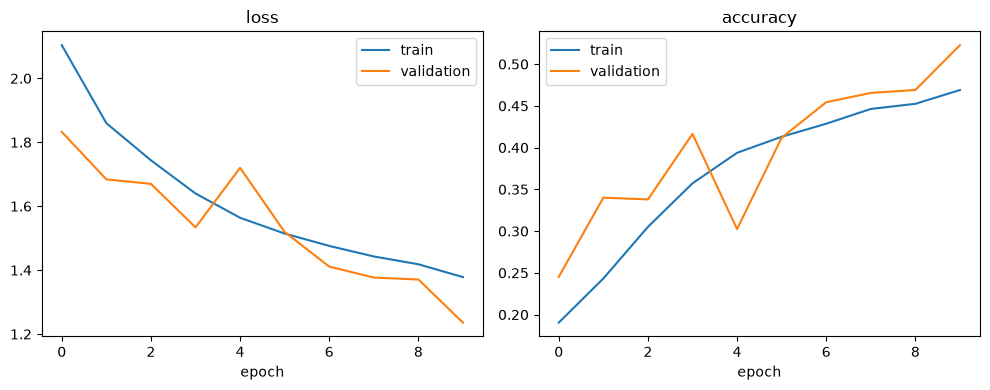

In [10]:
loss, acc = model.evaluate(test_ds, verbose=0)
print(f'Test accuracy: {acc:.4f}   Test loss: {loss:.4f}')

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for i, metric in enumerate(['loss', 'accuracy']):
    ax[i].plot(history.history[metric], label='train')
    ax[i].plot(history.history['val_' + metric], label='validation')
    ax[i].set_title(metric)
    ax[i].set_xlabel('epoch')
    ax[i].legend()
plt.tight_layout()
plt.show()

              precision    recall  f1-score   support

       angry     0.4155    0.3873    0.4009       958
     disgust     0.2113    0.5045    0.2979       111
        fear     0.3943    0.1494    0.2167      1024
       happy     0.6507    0.8630    0.7419      1774
     neutral     0.4589    0.4939    0.4758      1233
         sad     0.4259    0.3248    0.3685      1247
    surprise     0.6094    0.7341    0.6659       831

    accuracy                         0.5203      7178
   macro avg     0.4523    0.4939    0.4525      7178
weighted avg     0.4991    0.5203    0.4952      7178



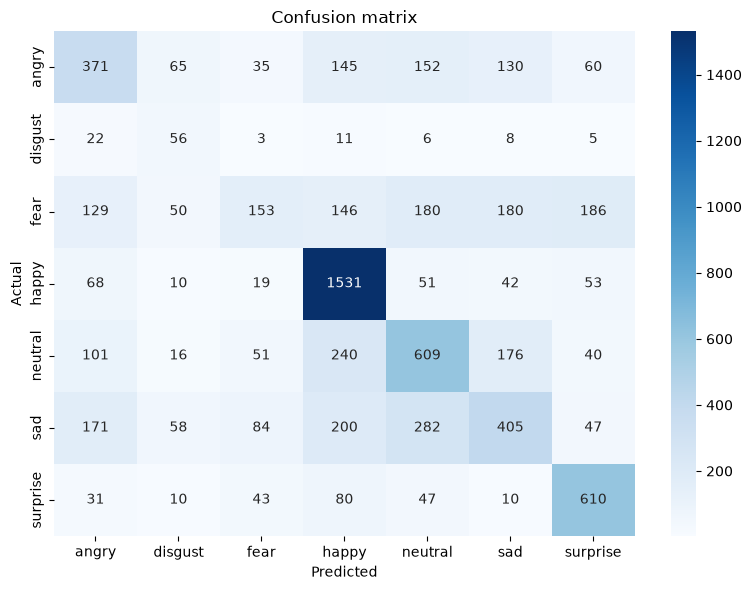

In [11]:
y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_pred = model.predict(test_ds, verbose=0).argmax(axis=1)
print(classification_report(y_true, y_pred, target_names=class_names, digits=4, zero_division=0))

plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion matrix')
plt.tight_layout()
plt.show()

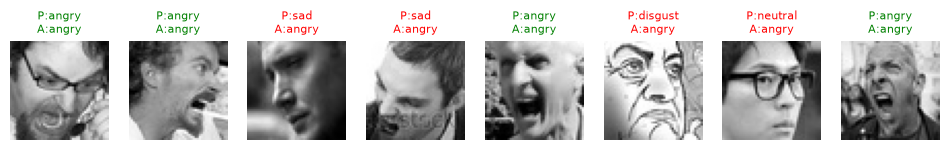

In [12]:
plt.figure(figsize=(12, 3))
for images, labels in test_ds.take(1):
    probs = model.predict(images[:8], verbose=0)
    for i in range(8):
        plt.subplot(1, 8, i + 1)
        plt.imshow(images[i].numpy().squeeze(), cmap='gray')
        p, t = int(probs[i].argmax()), int(labels[i])
        plt.title(f'P:{class_names[p]}\nA:{class_names[t]}', fontsize=8,
                  color='green' if p == t else 'red')
        plt.axis('off')
plt.show()

## Save and single-image inference

In [13]:
model.save('emotion_cnn_final.keras')
print('Saved: best_emotion_cnn.keras and emotion_cnn_final.keras')


def predict_image(path):
    img = keras.utils.load_img(path, color_mode='grayscale', target_size=IMG)
    x = keras.utils.img_to_array(img)[None, ...]
    probs = model.predict(x, verbose=0)[0]
    plt.imshow(img, cmap='gray')
    plt.axis('off')
    plt.title(f'{class_names[probs.argmax()]} ({probs.max():.1%})')
    plt.show()
    return dict(zip(class_names, probs.round(4)))

Saved: best_emotion_cnn.keras and emotion_cnn_final.keras
